Imports

In [1]:
%load_ext autoreload
%autoreload 2

from src.utils.data_io import load_dataset, save_pipeline
from src.classification import (
    split_data, run_models, plot_f1, plot_confusion_matrices, evaluate_best, plot_report_metrics,
)

c:\Users\Administrator\Projects\Briefs\Brief 3 - CardProfiler\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Init Mlflow

In [2]:
from src.mlflow import initialize_mlflow

initialize_mlflow()

Import data

In [3]:
data = load_dataset('labeled')
data.shape

(8949, 12)

Split

In [4]:
x_train, x_test, y_train, y_test = split_data(data)
x_train.shape, x_test.shape

((7159, 7), (1790, 7))

Models

In [5]:
result = run_models(x_train, y_train, x_test, y_test)
result.sort_values(by='f1', ascending=False)

c:\Users\Administrator\Projects\Briefs\Brief 3 - CardProfiler\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Administrator\Projects\Briefs\Brief 3 - CardProfiler\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Administrator\Projects\Briefs\Brief 3 - CardProfiler\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
2026/10/10

,name,duration,model,best_params,accuracy,precision,recall,f1,model_uri
2,RandomForestClassifier,4.170428,"(StandardScaler(), (DecisionTreeClassifier(max...","{'classifier__max_depth': 10, 'classifier__max...",0.964520,0.965179,0.964915,0.964986,models:/m-b66b0baa0e824abbb755c69df65907f1
1,DecisionTreeClassifier,0.618218,"(StandardScaler(), DecisionTreeClassifier(crit...","{'classifier__criterion': 'entropy', 'classifi...",0.938540,0.940076,0.940268,0.940043,models:/m-3bd402dea04d42a7bfe0dd71e1534e0e
3,SVC,0.698205,"(StandardScaler(), SVC(C=10, random_state=42))","{'classifier__C': 10, 'classifier__gamma': 'sc...",0.937982,0.937189,0.939785,0.938212,models:/m-26208f67c8ba41ceb55ad64999f2c81c
0,LogisticRegression,3.961226,"(StandardScaler(), LogisticRegression(C=1, pen...","{'classifier__C': 1, 'classifier__penalty': 'l1'}",0.897473,0.897121,0.900357,0.897993,models:/m-b59cc85abb564d01b182d0c5df5b7843


F1 comparison

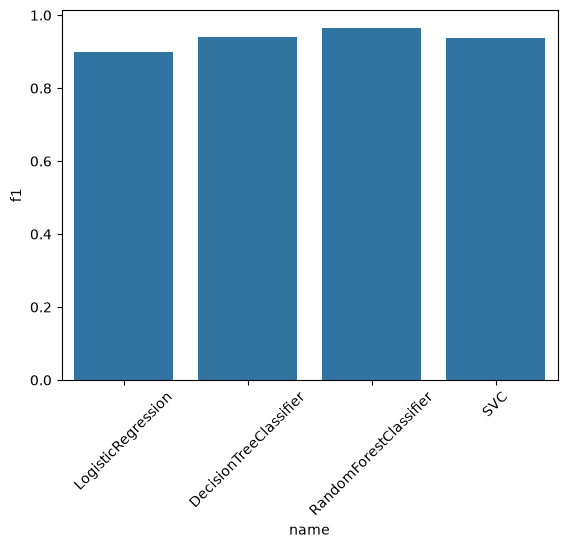

In [6]:
plot_f1(result)

Confusion matrices

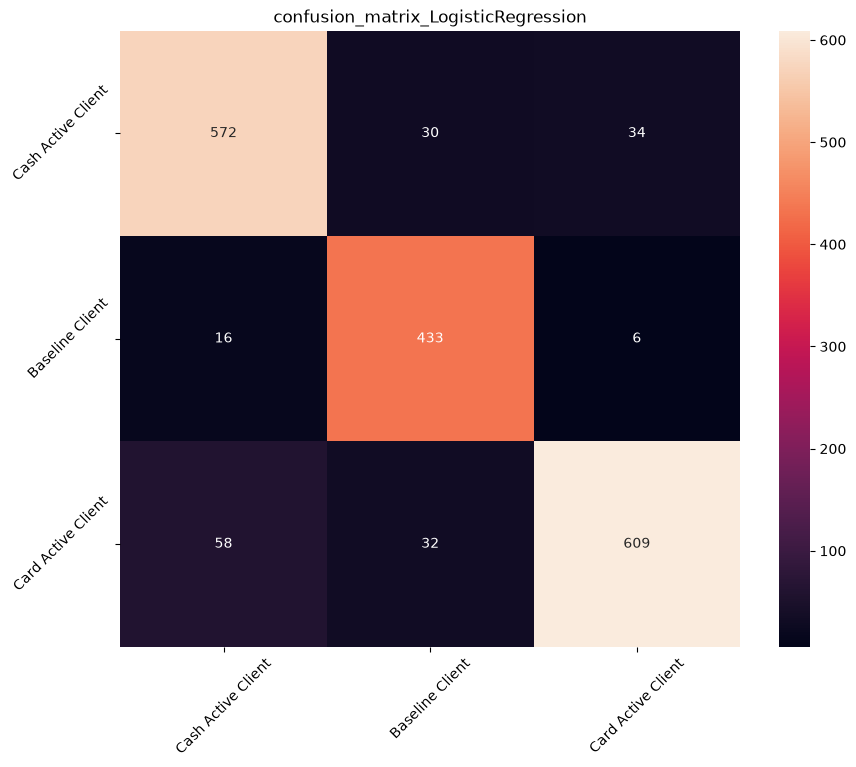

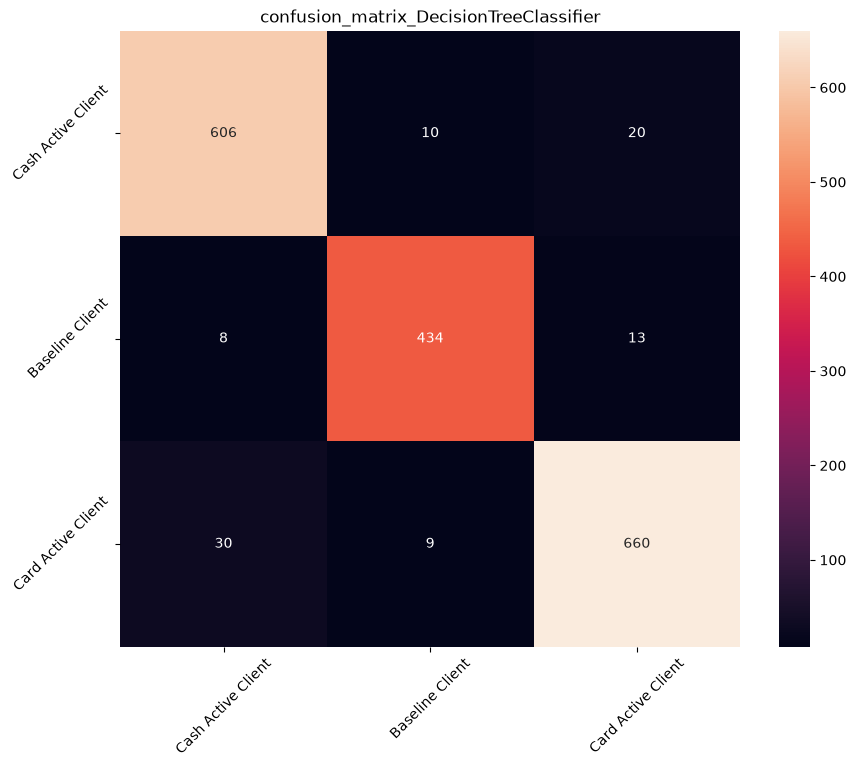

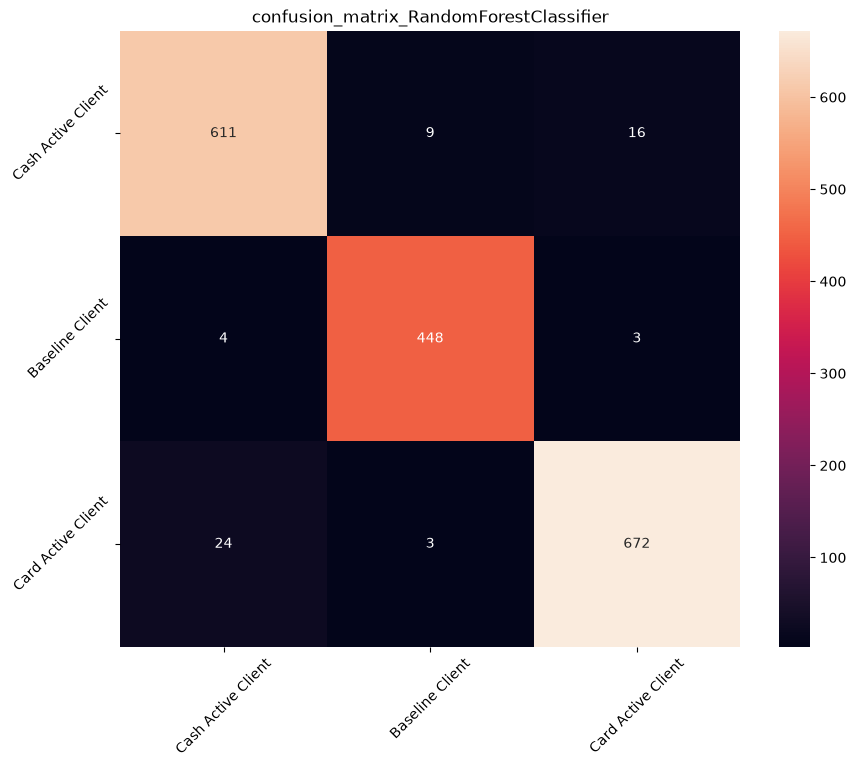

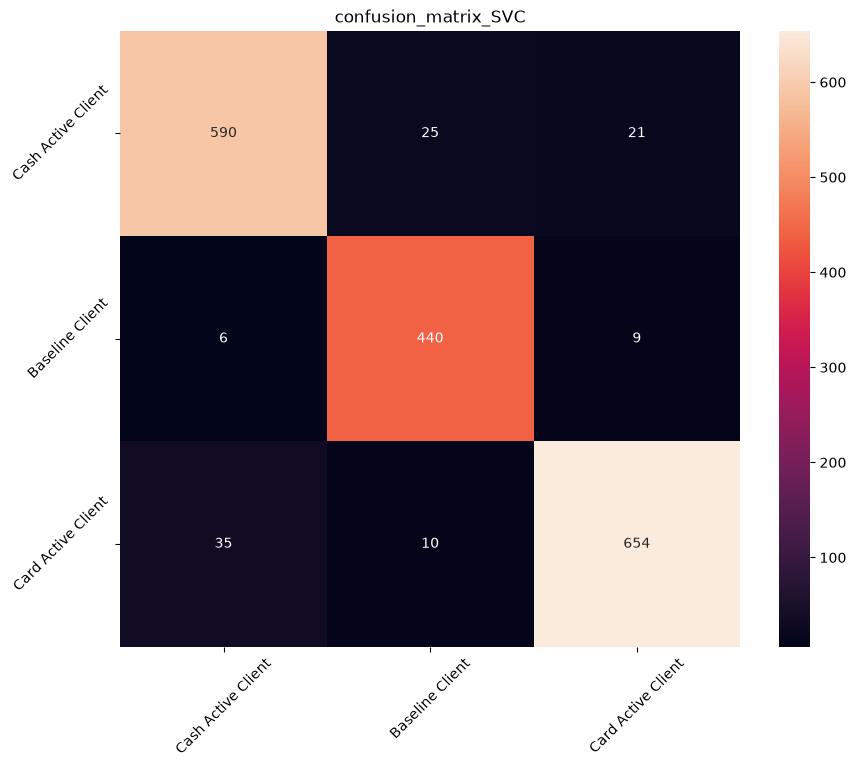

In [7]:
for i in range(0, len(result)):
    plot_confusion_matrices(f"confusion_matrix_{result.loc[i, 'name']}", result.loc[i, "model"].predict(x_test), y_test)


Best model report

In [8]:
from src.mlflow import name_champion


best_model, best_model_uri, report, accuracy = evaluate_best(result, x_test, y_test)
report
version = name_champion(best_model_uri)
version

Successfully registered model 'classification_champs'.
Created version '1' of model 'classification_champs'.


<ModelVersion: aliases=[], creation_timestamp=1791663800699, current_stage='None', deployment_job_state=None, description=None, last_updated_timestamp=1791663800699, metrics=None, model_id=None, name='classification_champs', params=None, run_id='9dbd2a077857407a94af08f03d491806', run_link=None, source='models:/m-b66b0baa0e824abbb755c69df65907f1', status='READY', status_message=None, tags={}, user_id=None, version=1, workspace='default'>

Serialize the best Model (Pipeline)

In [9]:
save_pipeline(best_model)

WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief 3 - CardProfiler/models/cardprofiler_pipeline.joblib')

Metrics per class

,Baseline Client,Card Active Client,Cash Active Client
precision,0.956182,0.973913,0.972504
recall,0.960692,0.984615,0.961373
f1-score,0.958431,0.979235,0.966906


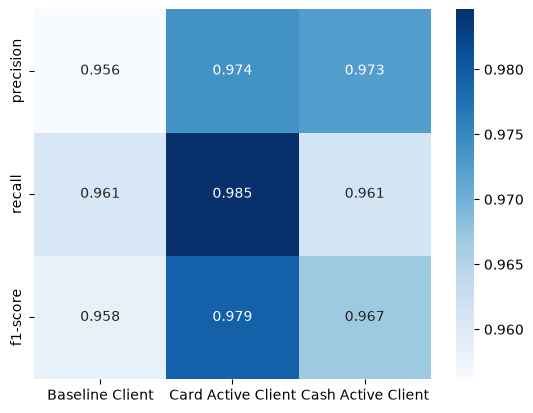

In [10]:
plot_report_metrics(report)

In [ ]:
from src.mlflow import load_champion
#machi err ghir kernel tani 
model = load_champion()

array(['Cash Active Client', 'Baseline Client', 'Card Active Client', ...,
       'Baseline Client', 'Card Active Client', 'Cash Active Client'],
      shape=(1790,), dtype=object)